# ПРОЕКТ: «Очистка и анализ данных»

**Команда:** Команда "КАФЕ☕"

**Список участников:** 
Ляшенко Михаил Сергеевич♛

Колосов Иван Вячеславович♚

Камашин Пётр Александрович♜

Гласинскас Кирилл Евгеньевич✠

**Датасет:** dirty_cafe_sales.csv

**Дата сдачи:** 26 ноября

---

## 📌 Инструкция
1. Выполняйте задания **по порядку**.
2. Код пишите в ячейках `[ ]:` под каждым заданием.
3. Там, где написано **«Объяснение»**, обязательно пишите текст. Это часть оценки!
4. В конце сохраните очищенный датасет `clean_Наименование_команды.csv`.

---
# ЭТАП 1. ОСМОТР И ОЧИСТКА (сделать 26.11)

## 1.1. Загрузка данных
Импортируйте `pandas` и загрузите ваш датасет.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('dirty_cafe_sales.csv')
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 1.2. Первичный осмотр
Выведите: размер таблицы, типы данных, первые 5 строк, описательную статистику.

**Объяснение:** Напишите текстом, что вы видите: какие типы неправильные, есть ли пропуски, есть ли странные значения (например, отрицательный возраст, дата в будущем).

In [3]:
# размер таблицы
print('Размер таблицы:', df.shape)
print()

# типы данных и пропуски
df.info()

Размер таблицы: (10000, 8)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


Первые 5 строк:

In [4]:
# первые 5 строк
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


Описательная статистика:

In [5]:
# описательная статистика (по всем колонкам, т.к. почти всё - object)
df.describe(include='all')

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


Посмотрим на значения в колонках:

In [ ]:
# посмотрим, какие значения вообще встречаются в колонках категорий
for col in ['Item', 'Payment Method', 'Location', 'Quantity', 'Price Per Unit']:
    print(col)
    print(df[col].value_counts(dropna=False))
    print('-' * 30)

Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64
------------------------------
Payment Method
Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64
------------------------------
Location
Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64
------------------------------
Quantity
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64
------------------------------
Price Per Unit
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179


**Что увидели:**

- В таблице **10 000 строк и 8 колонок**. Полных дублей пока не видно (`Transaction ID` уникален у всех 10 000 строк).
- **Типы данных неправильные:** все 8 колонок имеют тип `object` (строки). Даже `Quantity`, `Price Per Unit`, `Total Spent` (это числа) и `Transaction Date` (это дата) прочитались как текст. Из-за этого `describe()` не показал нормальную статистику (среднее, min, max).
- **Есть пропуски** (`NaN`): больше всего в `Location` (3265) и `Payment Method` (2579), в остальных колонках от 138 до 333.
- **Есть странные значения-заглушки:** в колонках встречаются слова `ERROR` и `UNKNOWN`, например в `Item` их 292 и 344. Это тоже по сути пропуски, просто записанные текстом.
- В `Transaction Date` самое частое значение `UNKNOWN` (159 раз), то есть и в дате есть мусор.
- Отрицательных значений в количестве и цене на глаз нет, `Quantity` от 1 до 5, цены от 1 до 5. Цена одного товара в разных строках одинаковая, это пригодится при очистке.

## 1.3. Дубликаты
Найдите количество полных дубликатов и удалите их.

**Объяснение:** Сколько дублей было? По какому принципу удаляли?

In [7]:
# полные дубликаты (все колонки совпадают)
print('Полных дубликатов:', df.duplicated().sum())

# на всякий случай проверим дубли только по ID транзакции
print('Дублей по Transaction ID:', df['Transaction ID'].duplicated().sum())

# удаляем (если их нет - ничего не изменится)
rows_before = len(df)
df = df.drop_duplicates()
print('Строк до:', rows_before, '| после:', len(df))

Полных дубликатов: 0
Дублей по Transaction ID: 0
Строк до: 10000 | после: 10000


**Дубликаты:**

Полных дубликатов оказалось **0**. Мы искали их через `df.duplicated()`, то есть строка считалась дублем, только если совпадают **все** колонки. Дополнительно проверили `Transaction ID`: он тоже уникален, так что повторных записей одной и той же транзакции нет. Код `drop_duplicates()` мы всё равно оставили в работе, чтобы он отработал, если данные обновятся, но размер таблицы не изменился (10 000 строк).

## 1.4. Пропуски
Посчитайте пропуски по колонкам. Решите, что с ними делать: удалить строки или заполнить.

**Объяснение:** Почему выбрали именно такой метод? 

In [8]:
# 1) считаем пропуски (NaN) как есть
print('Пропуски NaN до обработки:')
print(df.isna().sum())

Пропуски NaN до обработки:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


Кроме обычных `NaN` в данных есть «скрытые» пропуски: слова `ERROR` и `UNKNOWN`. Pandas их пропусками не считает, поэтому ищем отдельно.

In [9]:
# 2) считаем «скрытые» пропуски - слова ERROR и UNKNOWN
for col in df.columns:
    n = df[col].isin(['ERROR', 'UNKNOWN']).sum()
    if n > 0:
        print(col, '->', n)

Item -> 636
Quantity -> 341
Price Per Unit -> 354
Total Spent -> 329
Payment Method -> 599
Location -> 696
Transaction Date -> 301


Заменяем их на `NaN`:

In [10]:
# заменяем ERROR и UNKNOWN на NaN, чтобы все пропуски выглядели одинаково
df = df.replace(['ERROR', 'UNKNOWN'], np.nan)

# числовые колонки пока строки, переводим в числа (иначе ничего не посчитать)
for col in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df[col] = pd.to_numeric(df[col])

print('Пропуски после замены:')
print(df.isna().sum())

Пропуски после замены:
Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64


Часть пропусков можно **восстановить**, а не удалять. Цена у каждого товара фиксированная, посмотрим какая:

In [11]:
# 3) восстанавливаем числа, которые можно посчитать
# у каждого товара цена всегда одна и та же, берем словарь цен из самих данных
price_map = df.groupby('Item')['Price Per Unit'].agg(lambda s: s.mode()[0])
print(price_map)

Item
Cake        3.0
Coffee      2.0
Cookie      1.0
Juice       3.0
Salad       5.0
Sandwich    4.0
Smoothie    4.0
Tea         1.5
Name: Price Per Unit, dtype: float64


Восстанавливаем, что можно:

In [12]:
# если не знаем товар, но цена уникальна (она есть только у одного товара) - восстанавливаем товар
# цены 3.0 и 4.0 неоднозначные (cake/juice и sandwich/smoothie), их не трогаем
unique_price = {1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}
mask = df['Item'].isna() & df['Price Per Unit'].isin(unique_price.keys())
print('Восстановим товар в', mask.sum(), 'строках')
df.loc[mask, 'Item'] = df.loc[mask, 'Price Per Unit'].map(unique_price)

# цена по товару
mask = df['Price Per Unit'].isna() & df['Item'].notna()
df.loc[mask, 'Price Per Unit'] = df.loc[mask, 'Item'].map(price_map)

# цена = сумма / количество
mask = df['Price Per Unit'].isna() & df['Total Spent'].notna() & df['Quantity'].notna()
df.loc[mask, 'Price Per Unit'] = df.loc[mask, 'Total Spent'] / df.loc[mask, 'Quantity']

# количество = сумма / цена
mask = df['Quantity'].isna() & df['Total Spent'].notna() & df['Price Per Unit'].notna()
df.loc[mask, 'Quantity'] = df.loc[mask, 'Total Spent'] / df.loc[mask, 'Price Per Unit']

# сумма = количество * цена
mask = df['Total Spent'].isna() & df['Quantity'].notna() & df['Price Per Unit'].notna()
df.loc[mask, 'Total Spent'] = df.loc[mask, 'Quantity'] * df.loc[mask, 'Price Per Unit']

print(df.isna().sum())

Восстановим товар в 468 строках
Transaction ID         0
Item                 501
Quantity              23
Price Per Unit         6
Total Spent           23
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64


Что осталось - заполняем или удаляем:

In [13]:
# 4) то, что восстановить не получилось
rows_before = len(df)

# в Item, Payment Method и Location пропусков очень много, удалять нельзя - заполняем отдельной категорией
for col in ['Item', 'Payment Method', 'Location']:
    df[col] = df[col].fillna('unknown')

# дата, количество и сумма - важные для анализа, их удаляем
df = df.dropna(subset=['Transaction Date', 'Quantity', 'Price Per Unit', 'Total Spent'])

print('Строк до:', rows_before, '| после:', len(df), '| удалено:', rows_before - len(df))
print()
print(df.isna().sum())

Строк до: 10000 | после: 9514 | удалено: 486

Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64


**Как работали с пропусками:**

Сначала заметили, что кроме `NaN` есть скрытые пропуски `ERROR` и `UNKNOWN`. Мы заменили их на `NaN`, и пропусков стало заметно больше (например, в `Location` 3961, в `Payment Method` 3178). Дальше действовали по шагам:

1. **Восстановили то, что можно посчитать.** `Total Spent = Quantity * Price Per Unit`, поэтому если известны две величины из трех, третью находим. Цену также берем по товару (у каждого товара она фиксирована). Если цена уникальна (1.0 - cookie, 1.5 - tea, 2.0 - coffee, 5.0 - salad), то по ней восстановили и название товара (468 строк). После этого пропусков в числовых колонках почти не осталось (23 в `Quantity`, 6 в `Price Per Unit`, 23 в `Total Spent`).
2. **`Item`, `Payment Method`, `Location` заполнили значением `unknown`.** Здесь пропусков очень много (в `Location` почти 40%), если их удалить, мы потеряем половину данных. Заполнять модой тоже нельзя: мы бы выдумали данные и исказили долю In-store/Takeaway. Поэтому оставили отдельную категорию, а при анализе её можно исключить.
3. **Удалили строки без даты, количества, цены или суммы.** Дату и сумму восстановить нельзя, а без них анализ продаж не имеет смысла. Таких строк оказалось 486 (около 4.9%), это немного.

Итого строк: 10 000 -> 9 514.

## 1.5. Типы данных и текст
Приведите типы к правильным: даты в `pd.to_datetime`, числа из текста в `int`/`float`. Уберите лишние пробелы в тексте и приведите регистр к нижнему.

**Объяснение:** Какие колонки были неправильного типа? Как чистили текст?

In [14]:
# типы ДО преобразования
print(df.dtypes)

Transaction ID          str
Item                    str
Quantity            float64
Price Per Unit      float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
dtype: object


Преобразуем типы и чистим текст:

In [15]:
# дата -> datetime
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

# количество должно быть целым
df['Quantity'] = df['Quantity'].astype(int)

# текст: убираем пробелы по краям и приводим к нижнему регистру
text_cols = ['Transaction ID', 'Item', 'Payment Method', 'Location']
for col in text_cols:
    df[col] = df[col].str.strip().str.lower()

# переименуем колонки в snake_case, так удобнее писать код
df.columns = ['transaction_id', 'item', 'quantity', 'price_per_unit',
              'total_spent', 'payment_method', 'location', 'transaction_date']

print(df.dtypes)
print()
df.head()

transaction_id                 str
item                           str
quantity                     int64
price_per_unit             float64
total_spent                float64
payment_method                 str
location                       str
transaction_date    datetime64[us]
dtype: object



,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,txn_1961373,coffee,2,2.0,4.0,credit card,takeaway,2023-09-08
1,txn_4977031,cake,4,3.0,12.0,cash,in-store,2023-05-16
2,txn_4271903,cookie,4,1.0,4.0,credit card,in-store,2023-07-19
3,txn_7034554,salad,2,5.0,10.0,unknown,unknown,2023-04-27
4,txn_3160411,coffee,2,2.0,4.0,digital wallet,in-store,2023-06-11


Проверим, что после `lower()` не осталось дублей в написании категорий:

In [16]:
# проверка: остались ли разные написания в категориях
for col in ['item', 'payment_method', 'location']:
    print(col, '->', sorted(df[col].unique()))

item -> ['cake', 'coffee', 'cookie', 'juice', 'salad', 'sandwich', 'smoothie', 'tea', 'unknown']
payment_method -> ['cash', 'credit card', 'digital wallet', 'unknown']
location -> ['in-store', 'takeaway', 'unknown']


**Типы и текст:**

- `Transaction Date` был строкой -> перевели в `datetime` через `pd.to_datetime`. Теперь можно доставать месяц и день недели.
- `Quantity`, `Price Per Unit`, `Total Spent` были строками (из-за слов ERROR/UNKNOWN). Перевели в числа через `pd.to_numeric` на шаге 1.4, а `Quantity` потом сделали целым (`int`), потому что нельзя купить 2.5 кофе.
- Текстовые колонки (`Transaction ID`, `Item`, `Payment Method`, `Location`) почистили через `str.strip()` (убрать пробелы по краям) и `str.lower()` (нижний регистр), чтобы `Coffee` и `coffee` не считались разными товарами. После проверки в каждой категории осталось только нужное количество значений.
- Дополнительно переименовали колонки в вид `snake_case` (`total_spent` вместо `Total Spent`), так удобнее писать код и SQL-запросы на втором этапе.

## 1.6. Поиск аномалий и выбросов
Иногда в данных есть значения, которые ломают статистику (например, возраст 999 лет, зарплата 0 рублей, отрицательное количество товаров).

1. Выберите одну числовую колонку (например, цену, возраст, количество).
2. Постройте для неё `boxplot` (ящик с усами) или найдите выбросы с помощью правила IQR.
3. Отфильтруйте эти строки (или замените их на `NaN`, если считаете, что они ошибочные).

**Объяснение:** В какой колонке нашли выбросы? Сколько их? Почему решили их удалить (или оставить)?

count    9514.000000
mean        8.920380
std         6.003809
min         1.000000
25%         4.000000
50%         8.000000
75%        12.000000
max        25.000000
Name: total_spent, dtype: float64


C:\Users\Isihast\AppData\Local\Temp\ipykernel_19136\4147772655.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['total_spent'], vert=False)


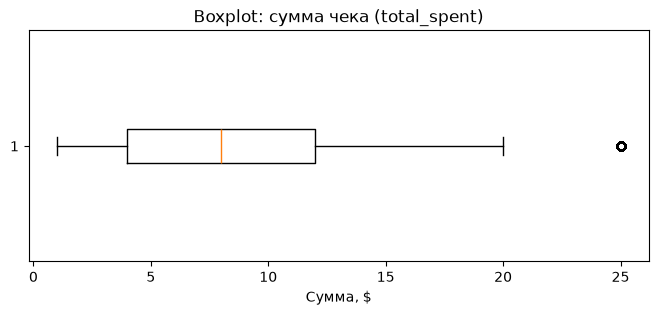

In [17]:
# берем колонку total_spent (сумма чека)
print(df['total_spent'].describe())

plt.figure(figsize=(8, 3))
plt.boxplot(df['total_spent'], vert=False)
plt.title('Boxplot: сумма чека (total_spent)')
plt.xlabel('Сумма, $')
plt.show()

Теперь считаем границы по правилу IQR:

In [18]:
# правило IQR
q1 = df['total_spent'].quantile(0.25)
q3 = df['total_spent'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print('Q1 =', q1, '| Q3 =', q3, '| IQR =', iqr)
print('Границы нормы: от', lower, 'до', upper)

outliers = df[(df['total_spent'] < lower) | (df['total_spent'] > upper)]
print('Выбросов по IQR:', len(outliers))

# отдельно проверим явные ошибки: нули и отрицательные значения
print('total_spent <= 0:', (df['total_spent'] <= 0).sum())
print('quantity <= 0:', (df['quantity'] <= 0).sum())
print('Даты от', df['transaction_date'].min().date(), 'до', df['transaction_date'].max().date())

Q1 = 4.0 | Q3 = 12.0 | IQR = 8.0
Границы нормы: от -8.0 до 24.0
Выбросов по IQR: 259
total_spent <= 0: 0
quantity <= 0: 0
Даты от 2023-01-01 до 2023-12-31


Дополнительная проверка логики данных:

In [19]:
# проверка: сумма должна равняться количество * цена
wrong = df[df['total_spent'] != df['quantity'] * df['price_per_unit']]
print('Строк, где сумма не сходится:', len(wrong))

Строк, где сумма не сходится: 0


**Выбросы:**

Мы выбрали колонку `total_spent` (сумма чека). По правилу IQR нормальными считаются значения от -8 до 24 (Q1 = 4, Q3 = 12, IQR = 8). Выше 24 оказалось **259 строк**, и все они равны 25.

Мы решили **оставить** их. Причина: 25 = 5 штук × 5$ (5 салатов). Это максимальное возможное количество (5) и максимальная цена (5), то есть **реальная покупка, а не ошибка**. На boxplot эти точки видны только потому, что распределение дискретное и верхняя граница чуть-чуть меньше 25. Если их удалить, мы потеряем самые крупные заказы, а именно они важны для анализа выручки.

Реальных аномалий не нашли: нулей и отрицательных значений в `quantity` и `total_spent` нет, все даты в пределах 2023 года, а `total_spent` везде равен `quantity * price_per_unit`.

## 1.7. Создание первого признака (Feature Engineering)
Даже на этапе очистки можно создать полезный признак. Например, если есть колонка с датой, можно вытащить из неё день недели или месяц. Если есть текст — можно посчитать его длину или количество слов.

1. Создайте **минимум 1 новую колонку** на основе существующих данных.
2. Выведите первые 5 строк, чтобы показать, что колонка появилась.

**Объяснение:** Какую колонку создали и зачем она может пригодиться на этапе анализа?

In [20]:
# новые признаки из даты
df['month'] = df['transaction_date'].dt.month
df['weekday'] = df['transaction_date'].dt.day_name()
df['is_weekend'] = df['transaction_date'].dt.dayofweek >= 5

df[['transaction_date', 'month', 'weekday', 'is_weekend', 'total_spent']].head()

,transaction_date,month,weekday,is_weekend,total_spent
0,2023-09-08,9,Friday,False,4.0
1,2023-05-16,5,Tuesday,False,12.0
2,2023-07-19,7,Wednesday,False,4.0
3,2023-04-27,4,Thursday,False,10.0
4,2023-06-11,6,Sunday,True,4.0


Проверим, что признак работает (средний чек в будни и выходные):

In [21]:
# быстрая проверка, что признаки работают
print(df.groupby('is_weekend')['total_spent'].mean().round(2))

is_weekend
False    8.93
True     8.89
Name: total_spent, dtype: float64


**Новые признаки:**

Из колонки `transaction_date` создали три признака: `month` (номер месяца), `weekday` (название дня недели) и `is_weekend` (True, если суббота или воскресенье).

Зачем: на этапе анализа можно смотреть сезонность продаж по месяцам и сравнивать выручку в разные дни недели. Сразу проверили `is_weekend`: средний чек в будни (8.93) и в выходные (8.89) почти одинаковый, то есть день недели на размер чека почти не влияет. Эти признаки удобно использовать в `GROUP BY` на этапе SQL.

## 1.8. Сохранение результата
Сохраните очищенный датасет в файл `clean_Наименование_команды.csv` без индекса.

In [22]:
df.to_csv('clean_cafe_team.csv', index=False)

# проверим, что файл сохранился нормально
check = pd.read_csv('clean_cafe_team.csv')
print(check.shape)

(9514, 11)


## 1.9. Мини-отчет в Markdown
Напишите небольшой текстовый отчет (5–7 предложений) по итогам очистки. Это черновик того, что вы будете рассказывать на защите.

**Что включить:**
- Сколько строк было и сколько стало после очистки?
- Какие главные проблемы были в данных (грязь, дубли, пропуски)?
- Какие методы очистки вы использовали и почему?
- С какими сложностями столкнулись?

**Мини-отчет:**

Мы с товарищами работали с датасетом `dirty_cafe_sales.csv` (продажи кафе за 2023 год): в нем было **10 000 строк и 8 колонок**, после очистки осталось **9 514 строк**. Главные проблемы в данных: все колонки были строками (в том числе числа и даты), было много пропусков (особенно в `Location` и `Payment Method`) и «скрытые» пропуски в виде слов `ERROR` и `UNKNOWN`. Полных дублей в данных не оказалось. Мы заменили ERROR/UNKNOWN на `NaN`, а затем восстановили часть значений по логике: `Total Spent = Quantity * Price Per Unit`, а цена у каждого товара фиксированная. Категориальные пропуски (`Item`, `Payment Method`, `Location`) заполнили значением `unknown`, потому что удалять такую долю данных нельзя, а строки без даты и суммы удалили (486 штук, около 4.9%). Выбросы по IQR (259 чеков по 25$) оставили, так как это реальная максимальная покупка, а не ошибка. Самой сложной частью было понять, что `UNKNOWN` и `ERROR` - это тоже пропуски, ведь `isna()` их не находит, и придумать, как восстановить значения вместо того чтобы просто удалять строки. Для анализа создали признаки `month`, `weekday` и `is_weekend`.

## **❤** 
